In [10]:
import warnings
warnings.filterwarnings("ignore")        # hide noisy library warnings

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Settings used by the rest of the notebook
SEED = 67                                # fixed seed so results are reproducible
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")         # clean chart style
pd.set_option("display.max_columns", 30) # show all columns when printing tables

In [11]:
df = pd.read_csv("../data/proj_machine_readings.csv", parse_dates=["timestamp"])

print(df.shape)
print("timestamp type:", df["timestamp"].dtype)
df.head()

(100000, 13)
timestamp type: datetime64[us]


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


In [12]:
# 1. Column types
print(df.dtypes)

# 2. Missing values in each column
print(df.isna().sum())
print("Temperature missing:", round(df["temperature"].isna().mean() * 100, 1), "%")

# 3. Duplicate rows
print("Duplicates:", df.duplicated().sum())

# 4. Min, max and average of each number column
df.describe()

timestamp                   datetime64[us]
machine_id                           int64
temperature                        float64
vibration                          float64
humidity                           float64
pressure                           float64
energy_consumption                 float64
machine_status                       int64
anomaly_flag                         int64
predicted_remaining_life             int64
failure_type                           str
downtime_risk                      float64
maintenance_required                 int64
dtype: object
timestamp                       0
machine_id                      0
temperature                 14000
vibration                       0
humidity                        0
pressure                        0
energy_consumption              0
machine_status                  0
anomaly_flag                    0
predicted_remaining_life        0
failure_type                    0
downtime_risk                   0
maintenance_require

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,downtime_risk,maintenance_required
count,100000,100000.000000,86000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2025-02-04 17:19:30,25.499330,75.034410,43.324232,54.995401,3.000405,2.747064,1.002050,0.089160,234.269160,0.089155,0.196970
min,2025-01-01 00:00:00,1.000000,35.550000,-106.980000,30.000000,1.000000,0.500000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,2025-01-18 08:39:45,13.000000,68.280000,37.220000,42.520000,2.000000,1.630000,1.000000,0.000000,97.000000,0.000000,0.000000
50%,2025-02-04 17:19:30,25.000000,75.090000,48.635000,54.980000,3.010000,2.740000,1.000000,0.000000,230.000000,0.000000,0.000000
75%,2025-02-22 01:59:15,38.000000,81.780000,59.250000,67.500000,4.000000,3.870000,1.000000,0.000000,365.000000,0.000000,0.000000
max,2025-03-11 10:39:00,50.000000,121.940000,113.800000,80.000000,5.000000,5.000000,2.000000,1.000000,499.000000,1.000000,1.000000
std,NaN,14.389439,10.036257,29.134306,14.437960,1.152399,1.297865,0.446193,0.284976,150.063062,0.284961,0.397711


Key findings: The dataset has 100,000 rows. Only temperature has missing values (14%). There are no duplicate rows. machine_id is a category label, not a number, so it is used for grouping only. All sensors stay within realistic ranges except vibration, which contains negative values (minimum -106.98) that are physically impossible. About 19.7% of readings require maintenance, so the classes are imbalanced.

In [13]:
negatives = (df["vibration"] < 0).sum()
print("Negative vibration rows:", negatives)
print("Percentage:", round(negatives / len(df) * 100, 2), "%")

Negative vibration rows: 6703
Percentage: 6.7 %


6.7% of vibration readings are negative, which is impossible. Before deciding how to fix them, we check whether they are linked to machine failure.

In [14]:
df["is_negative"] = df["vibration"] < 0

for col in ["machine_status", "failure_type", "anomaly_flag", "maintenance_required"]:
    print(col)
    print((df.groupby(col)["is_negative"].mean() * 100).round(2))

    # Chi-square: is the % of negatives different between groups, or just luck?
    p = stats.chi2_contingency(pd.crosstab(df[col], df["is_negative"]))[1]
    print("p-value:", round(p, 3))
    print()

machine_status
machine_status
0    6.43
1    6.73
2    6.72
Name: is_negative, dtype: float64
p-value: 0.509

failure_type
failure_type
Electrical Fault    6.90
Normal              6.70
Overheating         6.59
Pressure Drop       7.11
Vibration Issue     6.62
Name: is_negative, dtype: float64
p-value: 0.955

anomaly_flag
anomaly_flag
0    6.71
1    6.64
Name: is_negative, dtype: float64
p-value: 0.82

maintenance_required
maintenance_required
0    6.71
1    6.67
Name: is_negative, dtype: float64
p-value: 0.829



The share of negative vibration readings is about 6.7% regardless of machine status, failure type, anomaly flag or maintenance requirement (chi-square p-values all well above 0.05). Negative vibration is therefore not associated with machine failure. This does not prove the cause, but it supports treating them as random sign errors.

In [16]:
# Size of each vibration value, ignoring the minus sign
df["vibration_abs"] = df["vibration"].abs()

# Group readings by size
size_group = pd.cut(df["vibration_abs"], bins=[0, 20, 40, 60, 80, 120], right=False)

# Count negative vs positive readings in each size group
table = pd.crosstab(size_group, df["is_negative"]).rename(columns={False: "positive", True: "negative"})
table["negative / positive"] = (table["negative"] / table["positive"]).round(3)
display(table)

# Extra check: the very smallest readings
near_zero = df[df["vibration_abs"] < 5]
print("Readings with size below 5:", len(near_zero),
      "-> negative share:", round(near_zero["is_negative"].mean() * 100, 1), "%")

is_negative,positive,negative,negative / positive
vibration_abs,,,
"[0, 20)",2072,185,0.089
"[20, 40)",21302,1485,0.070
"[40, 60)",46389,3351,0.072
"[60, 80)",21397,1531,0.072
"[80, 120)",2137,151,0.071


Readings with size below 5: 122 -> negative share: 23.0 %


The negative-to-positive ratio is about 0.07 at every vibration level, consistent with random sign errors. It is slightly higher in the 0–20 range (about 34 extra negatives, around 20 of them below 5), possibly values that were naturally near zero. This is too few rows to change our decision.

In [17]:
print("Lowest vibration_abs:", round(df["vibration_abs"].min(), 2))
print("Negative values left:", (df["vibration_abs"] < 0).sum())
print("Skew before:", round(df["vibration"].skew(), 2))
print("Skew after: ", round(df["vibration_abs"].skew(), 2))

Lowest vibration_abs: 0.02
Negative values left: 0
Skew before: -2.19
Skew after:  0.01


In [22]:
# Keep only rows where temperature is known and clearly BELOW 90, and drop the few rows sitting
# exactly on the vibration threshold of 80 (values are rounded to 2 decimals, so those are borderline)
cool = df[df["temperature"].notna() & (df["temperature"] < 90) & (df["vibration_abs"] != 80)].copy()

cool["sign"] = np.where(cool["vibration"] < 0, "negative", "positive")
cool["size_group"] = pd.cut(cool["vibration_abs"], bins=[0, 20, 40, 50, 60, 80, 120], right=False)

proof = cool.groupby(["sign", "size_group"], observed=True)["anomaly_flag"].agg(rows="count", anomalies="sum", rate="mean")
proof["rate"] = (proof["rate"] * 100).round(1)
display(proof)

# Every negative reading with a size above 80
big_negative = (df["vibration"] < 0) & (df["vibration_abs"] > 80)
print("Negative readings with size above 80:", big_negative.sum())
print("Share flagged as anomaly:", df.loc[big_negative, "anomaly_flag"].mean())

# The only rows that disagree with the rule sit exactly on a threshold (values are rounded to 2 decimals)
known = df[df["temperature"].notna()]
rule = (known["temperature"] > 90) | (known["vibration_abs"] > 80)
disagree = known[rule != known["anomaly_flag"].astype(bool)]
print("Rows disagreeing with the rule:", len(disagree), "of", len(known))
disagree[["temperature", "vibration", "vibration_abs", "anomaly_flag"]]

rows  anomalies   rate
sign     size_group                         
negative [0, 20)       139          0    0.0
         [20, 40)     1107          0    0.0
         [40, 50)     1234          0    0.0
         [50, 60)     1265          0    0.0
         [60, 80)     1146          0    0.0
         [80, 120)     110        110  100.0
positive [0, 20)      1668          0    0.0
         [20, 40)    17166          0    0.0
         [40, 50)    18858          0    0.0
         [50, 60)    18577          0    0.0
         [60, 80)    17144          0    0.0
         [80, 120)    1741       1741  100.0

Negative readings with size above 80: 151
Share flagged as anomaly: 1.0
Rows disagreeing with the rule: 5 of 86000


,temperature,vibration,vibration_abs,anomaly_flag
8005,73.05,80.00,80.00,1
27676,90.00,46.31,46.31,1
32761,90.00,53.44,53.44,1
72925,70.73,80.00,80.00,1
79388,90.00,62.64,62.64,1


We use vibration_abs instead of imputation. The negatives are random sign errors, so the magnitude is still a valid reading. The anomaly flag treats negative and positive vibration identically: with temperature clearly below 90 °C, no reading of size below 80 is flagged (negative or positive), and every reading above 80 is flagged. All 151 negative readings above 80 are flagged. Only 5 of 86,000 rows with a known temperature disagree with the rule, and each sits exactly on a threshold (temperature 90.00 or vibration 80.00); since the data is rounded to 2 decimals, the unrounded values could fall on either side. Imputation would replace 6,703 recoverable readings with one repeated value and lose information. No rows are deleted.

In [19]:
df["temp_missing"] = df["temperature"].isna().astype(int)

for col in ["machine_status", "anomaly_flag", "maintenance_required", "failure_type", "machine_id"]:
    rate = (df.groupby(col)["temp_missing"].mean() * 100).round(1)
    p = stats.chi2_contingency(pd.crosstab(df[col], df["temp_missing"]))[1]
    print(f"{col}: missing rate from {rate.min()}% to {rate.max()}%, p-value = {p:.3f}")

machine_status: missing rate from 13.8% to 14.0%, p-value = 0.828
anomaly_flag: missing rate from 13.8% to 14.0%, p-value = 0.528
maintenance_required: missing rate from 13.8% to 14.1%, p-value = 0.312
failure_type: missing rate from 12.5% to 14.2%, p-value = 0.412
machine_id: missing rate from 12.6% to 15.7%, p-value = 0.899


In [20]:
rng = np.random.default_rng(SEED)

# Pretend 14% of the KNOWN temperatures are missing, then fill them in and measure the error
known = df[df["temperature"].notna()]
hide = rng.random(len(known)) < 0.14
train, test = known[~hide], known[hide]
truth = test["temperature"]

for name, fill in {"mean": train["temperature"].mean(), "median": train["temperature"].median()}.items():
    error = fill - truth
    print(f"{name:6s} fill = {fill:.2f}   RMSE = {np.sqrt((error ** 2).mean()):.2f}   MAE = {error.abs().mean():.2f}")

print("Spread (std) of temperature:", round(known["temperature"].std(), 2))

hot = truth > 90
print("Hidden readings above 90 °C:", hot.sum(), "| median fill value:", round(train["temperature"].median(), 2),
      "(below 90, so none of them can be recovered)")

mean   fill = 75.05   RMSE = 9.99   MAE = 8.01
median fill = 75.08   RMSE = 9.99   MAE = 8.01
Spread (std) of temperature: 10.04
Hidden readings above 90 °C: 734 | median fill value: 75.08 (below 90, so none of them can be recovered)


Temperature is missing completely at random (all chi-square p-values above 0.05), so imputation is appropriate. Mean and median perform identically because temperature is symmetric. We choose the median (robust to extreme values) plus a temp_missing marker. A constant fill cannot recover readings above 90 °C, so some overheating events are invisible in rows with a missing temperature; this is a limit of the data. In the pipeline, the median will be calculated from the training data only to avoid leaking test information. For now we keep the original NaN values so that plots are not distorted.

In [21]:
df = df.drop(columns=["is_negative"], errors="ignore")
df.columns.tolist()

['timestamp',
 'machine_id',
 'temperature',
 'vibration',
 'humidity',
 'pressure',
 'energy_consumption',
 'machine_status',
 'anomaly_flag',
 'predicted_remaining_life',
 'failure_type',
 'downtime_risk',
 'maintenance_required',
 'vibration_abs',
 'temp_missing']

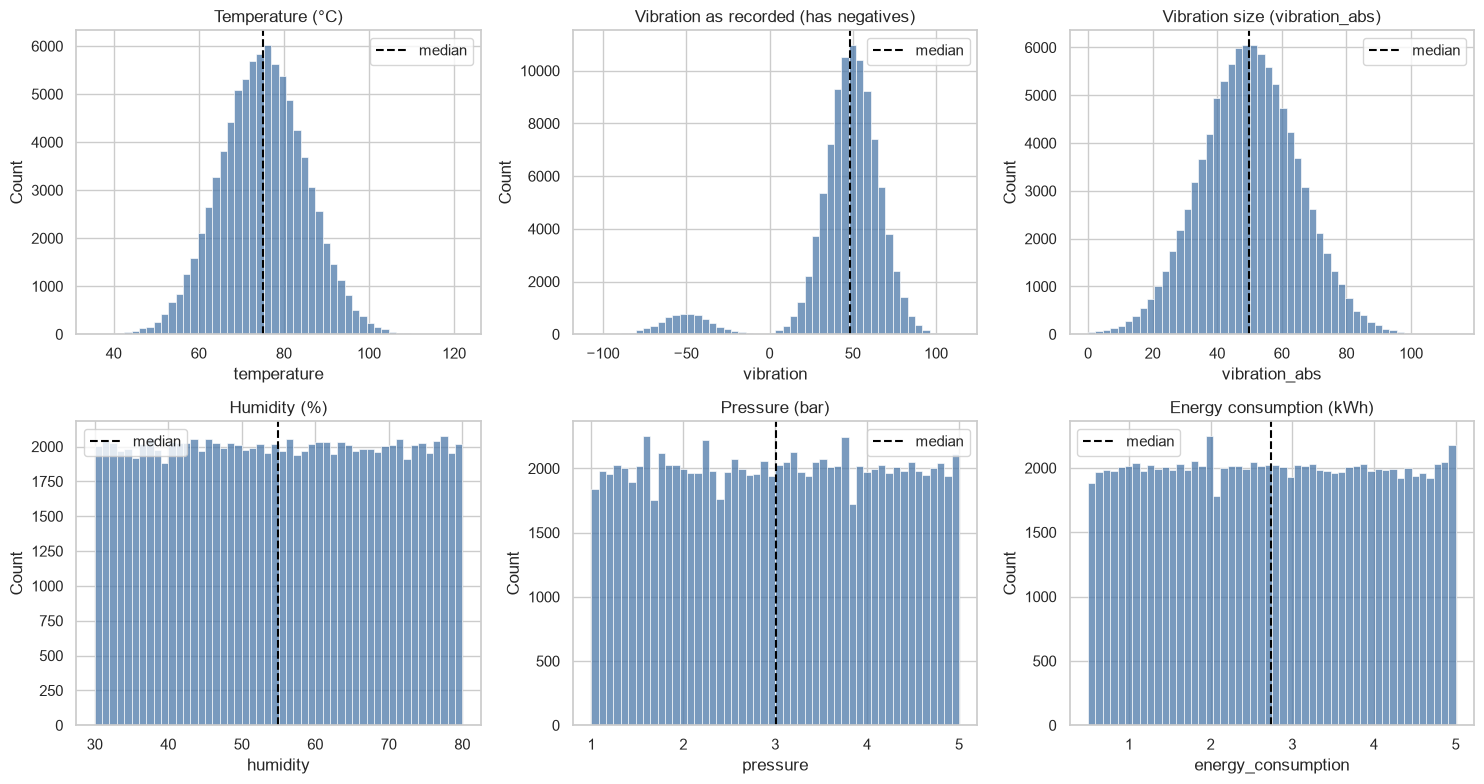

temperature          -0.01
vibration            -2.19
vibration_abs         0.01
humidity              0.00
pressure             -0.00
energy_consumption    0.01
dtype: float64


In [23]:
cols = [
    ("temperature", "Temperature (°C)"),
    ("vibration", "Vibration as recorded (has negatives)"),
    ("vibration_abs", "Vibration size (vibration_abs)"),
    ("humidity", "Humidity (%)"),
    ("pressure", "Pressure (bar)"),
    ("energy_consumption", "Energy consumption (kWh)"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), cols):
    sns.histplot(df[col].dropna(), bins=50, ax=ax, color="#4C78A8")
    ax.axvline(df[col].median(), color="black", linestyle="--", label="median")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

# Skew: 0 = symmetric, large negative = long tail to the left
print(df[["temperature", "vibration", "vibration_abs", "humidity", "pressure", "energy_consumption"]].skew().round(2))

Temperature and vibration size are bell-shaped and symmetric. The raw vibration histogram shows a second, smaller bump around -50, a mirror image of the main bump at +50, which is what random sign errors look like; taking the absolute value merges them into one bell (skew from -2.19 to about 0.01). Humidity, pressure and energy consumption are flat across their ranges (30–80 %, 1–5 bar, 0.5–5 kWh), unlike real physical sensors, which suggests they may behave like random noise. We test later whether they relate to the target.

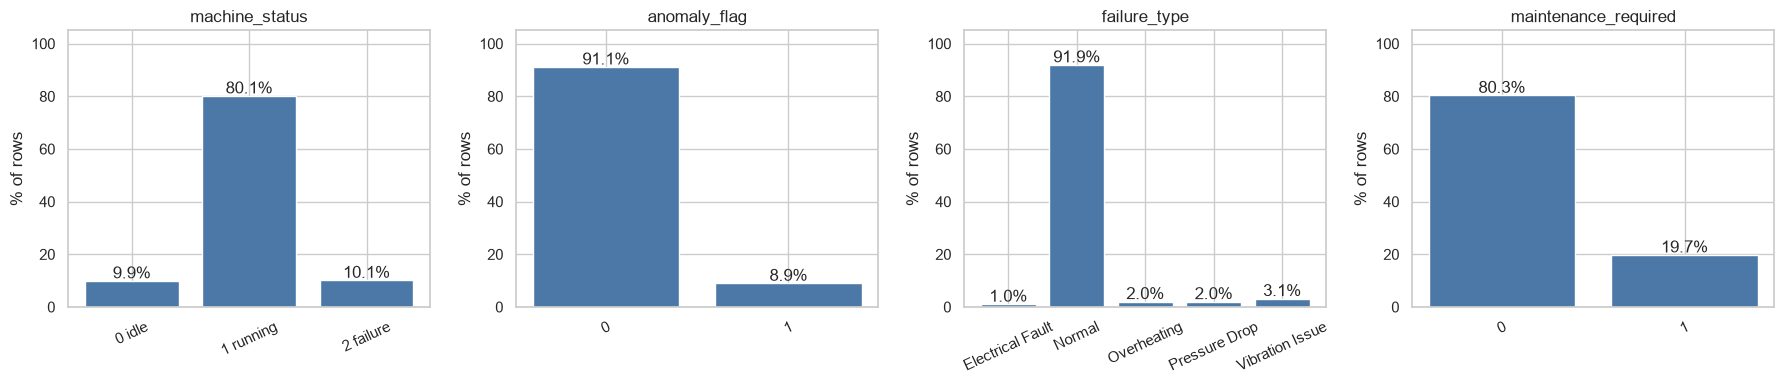

In [24]:
labels = {"machine_status": {0: "0 idle", 1: "1 running", 2: "2 failure"}}
cats = ["machine_status", "anomaly_flag", "failure_type", "maintenance_required"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cats):
    pct = df[col].value_counts(normalize=True).sort_index() * 100
    names = [labels.get(col, {}).get(i, str(i)) for i in pct.index]
    ax.bar(names, pct.values, color="#4C78A8")
    for i, v in enumerate(pct.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center")
    ax.set_title(col)
    ax.set_ylabel("% of rows")
    ax.set_ylim(0, 105)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

Machines are running 80.1% of the time, idle 9.9% and in failure 10.1%. Only 8.9% of readings are flagged as anomalies and 91.9% have failure type Normal; the four fault types are rare (1–3% each). The target maintenance_required is 19.7% positive.

maintenance_required
0    80303
1    19697
Name: count, dtype: int64
Share needing maintenance: 19.7 %
Ratio no : yes = 4.08 : 1
Accuracy of always predicting 'no maintenance': 80.3 %


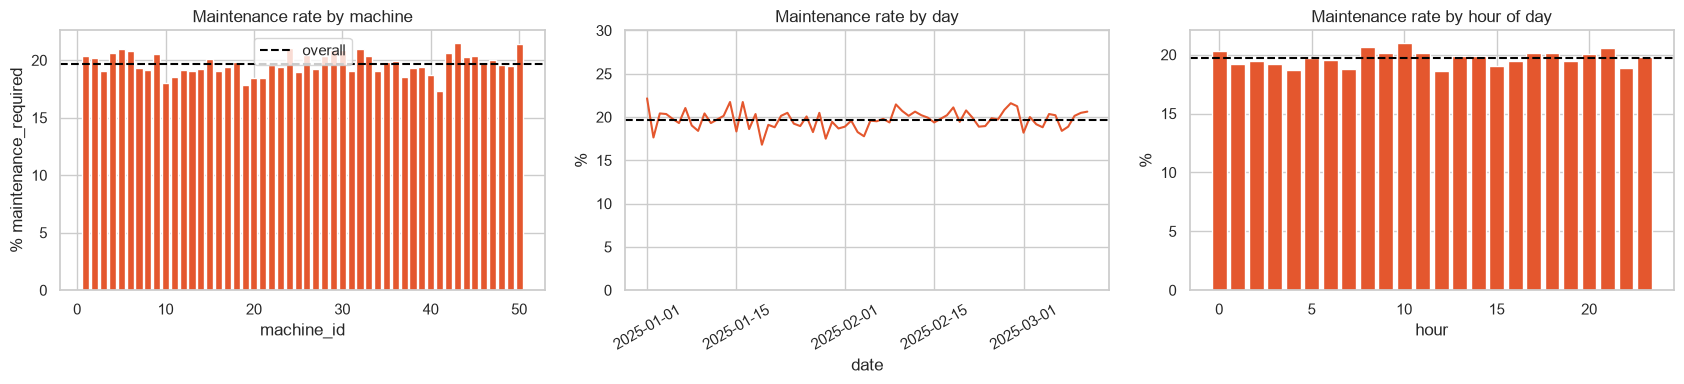

Machine vs maintenance: p-value = 0.238
Hour vs maintenance:    p-value = 0.35


In [25]:
target = "maintenance_required"
overall = df[target].mean() * 100

# 1. Class balance
counts = df[target].value_counts()
print(counts)
print("Share needing maintenance:", round(overall, 1), "%")
print("Ratio no : yes =", round(counts[0] / counts[1], 2), ": 1")
print("Accuracy of always predicting 'no maintenance':", round(counts[0] / len(df) * 100, 1), "%")

# 2. Maintenance rate by machine, by day and by hour of day
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

by_machine = df.groupby("machine_id")[target].mean() * 100
axes[0].bar(by_machine.index, by_machine.values, color="#E4572E")
axes[0].axhline(overall, color="black", linestyle="--", label="overall")
axes[0].set(title="Maintenance rate by machine", xlabel="machine_id", ylabel="% maintenance_required")
axes[0].legend()

by_day = df.set_index("timestamp")[target].resample("D").mean() * 100
axes[1].plot(by_day.index, by_day.values, color="#E4572E")
axes[1].axhline(overall, color="black", linestyle="--")
axes[1].set(title="Maintenance rate by day", xlabel="date", ylabel="%", ylim=(0, 30))
axes[1].tick_params(axis="x", rotation=30)

by_hour = df.groupby(df["timestamp"].dt.hour)[target].mean() * 100
axes[2].bar(by_hour.index, by_hour.values, color="#E4572E")
axes[2].axhline(overall, color="black", linestyle="--")
axes[2].set(title="Maintenance rate by hour of day", xlabel="hour", ylabel="%")

plt.tight_layout()
plt.show()

# 3. Chi-square tests: are the differences between machines / hours bigger than luck?
p_machine = stats.chi2_contingency(pd.crosstab(df["machine_id"], df[target]))[1]
p_hour = stats.chi2_contingency(pd.crosstab(df["timestamp"].dt.hour, df[target]))[1]
print("Machine vs maintenance: p-value =", round(p_machine, 3))
print("Hour vs maintenance:    p-value =", round(p_hour, 3))

About 20% of readings require maintenance (a ratio of about 4 : 1). A model that always predicts "no maintenance" would be 80.3% accurate, so accuracy is misleading; we will focus on recall, precision, F1 and PR-AUC for the maintenance class. The maintenance rate is similar across machines (17.3–21.5%, chi-square p = 0.238), days and hours of the day (p = 0.35); these differences are what chance alone would produce. We found no evidence of a machine or time effect, so machine_id and time-of-day will not be used as predictors.

ALL ROWS


,median (no maintenance),median (maintenance),effect size r,p-value
sensor,,,,
temperature,74.23,80.655,0.343,0.000
vibration_abs,49.53,51.900,0.117,0.000
humidity,55.01,54.850,-0.006,0.227
pressure,3.01,2.990,-0.003,0.539
energy_consumption,2.74,2.750,0.002,0.663


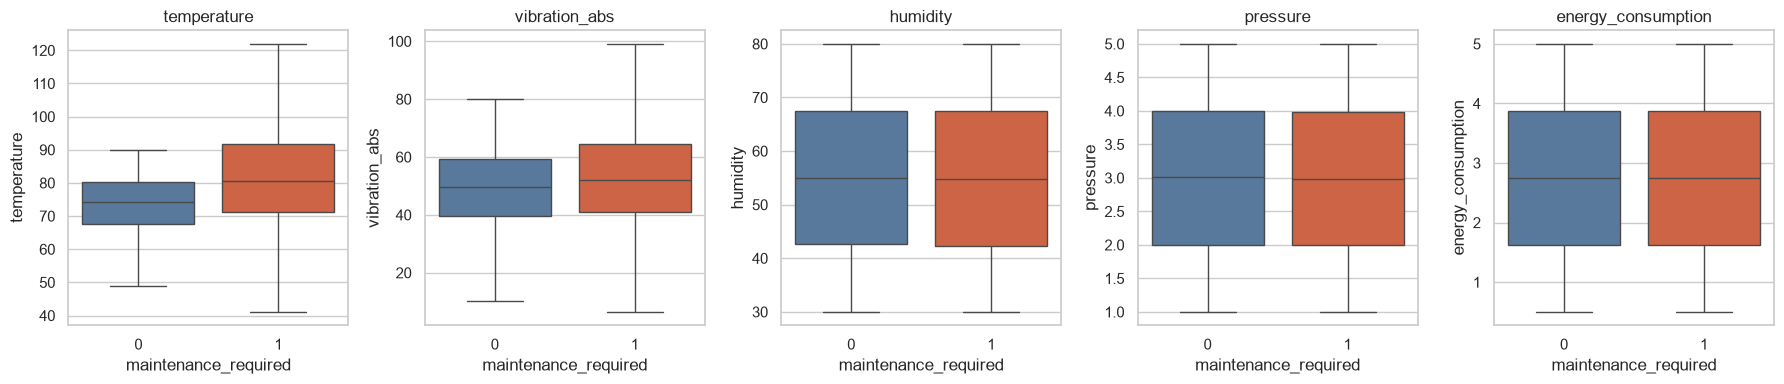

ONLY ROWS WITHOUT AN ANOMALY FLAG (anomaly_flag == 0)


,median (no maintenance),median (maintenance),effect size r,p-value
sensor,,,,
temperature,74.23,74.10,-0.000,0.960
vibration_abs,49.53,49.58,0.002,0.675
humidity,55.01,54.77,-0.008,0.164
pressure,3.01,3.00,-0.001,0.801
energy_consumption,2.74,2.73,-0.005,0.361


In [26]:
sensors = ["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption"]
target = "maintenance_required"

def compare_sensors(data):
    """For each sensor: median per group, effect size (r) and p-value (Mann-Whitney test)."""
    rows = []
    for col in sensors:
        yes = data.loc[data[target] == 1, col].dropna()
        no = data.loc[data[target] == 0, col].dropna()
        u, p = stats.mannwhitneyu(yes, no)
        rows.append({"sensor": col,
                     "median (no maintenance)": no.median(),
                     "median (maintenance)": yes.median(),
                     "effect size r": 2 * u / (len(yes) * len(no)) - 1,
                     "p-value": p})
    return pd.DataFrame(rows).set_index("sensor").round(3)

print("ALL ROWS")
display(compare_sensors(df))

# Boxplots: one per sensor, split by the target
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, sensors):
    sns.boxplot(data=df, x=target, y=col, hue=target, palette=["#4C78A8", "#E4572E"],
                legend=False, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("ONLY ROWS WITHOUT AN ANOMALY FLAG (anomaly_flag == 0)")
display(compare_sensors(df[df["anomaly_flag"] == 0]))

On all rows, temperature (effect size r = 0.34, medium) and vibration size (r = 0.12, small) are higher when maintenance is required, while humidity, pressure and energy consumption show no difference (|r| < 0.01, p > 0.05). However, when the rows flagged as anomalies are removed, no sensor separates the two groups any more (all |r| < 0.01). So the sensors only help through extreme temperature and vibration readings; for the remaining 91% of readings, the sensor values alone say almost nothing about whether maintenance is required. This limits what a sensor-only model can achieve.

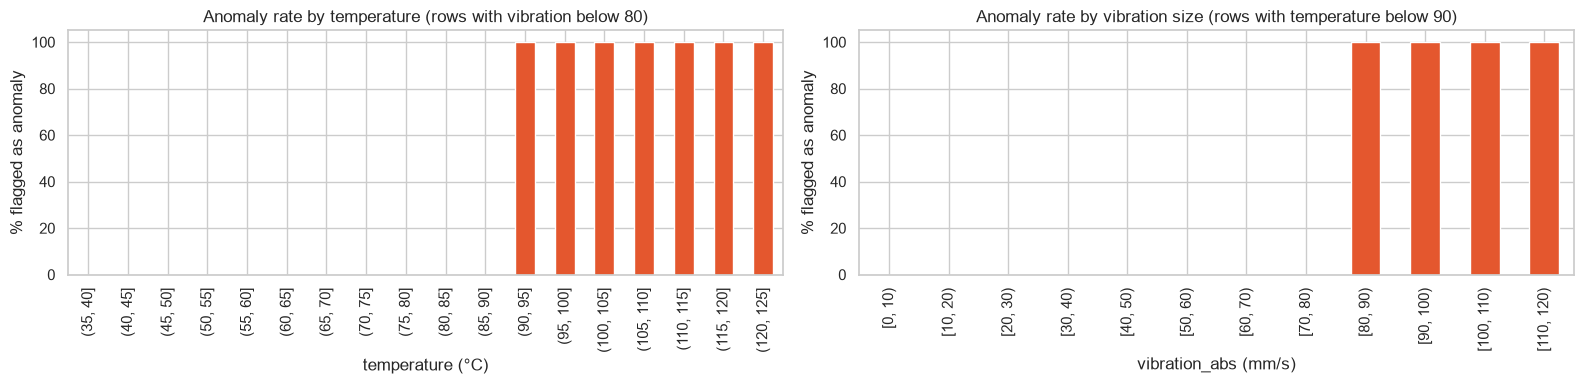

Rows above 90 °C: 5832 -> share flagged: 1.0
Rows with temperature <= 90 and vibration <= 80: 78317 -> share flagged: 6e-05
Anomaly rate, temperature missing: 8.77 %
Anomaly rate, temperature known:   8.94 %
Anomalies whose cause is hidden: 922 of 8916 = 10.3 %


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Temperature: use only rows with normal vibration, so vibration cannot be the trigger
calm = df[df["vibration_abs"] < 80]
t_bins = pd.cut(calm["temperature"], bins=np.arange(30, 130, 5))
t_rate = calm.groupby(t_bins, observed=True)["anomaly_flag"].mean() * 100
t_rate.plot(kind="bar", color="#E4572E", ax=axes[0])
axes[0].set(title="Anomaly rate by temperature (rows with vibration below 80)",
            xlabel="temperature (°C)", ylabel="% flagged as anomaly")

# Vibration: use only rows with temperature below 90, so temperature cannot be the trigger
cool = df[df["temperature"] < 90]
v_bins = pd.cut(cool["vibration_abs"], bins=np.arange(0, 130, 10), right=False)
v_rate = cool.groupby(v_bins, observed=True)["anomaly_flag"].mean() * 100
v_rate.plot(kind="bar", color="#E4572E", ax=axes[1])
axes[1].set(title="Anomaly rate by vibration size (rows with temperature below 90)",
            xlabel="vibration_abs (mm/s)", ylabel="% flagged as anomaly")

plt.tight_layout()
plt.show()

# Test the rule: anomaly = temperature above 90 OR vibration size above 80
known_temp = df[df["temperature"].notna()]
hot = known_temp["temperature"] > 90
print("Rows above 90 °C:", hot.sum(), "-> share flagged:", known_temp.loc[hot, "anomaly_flag"].mean())

normal = known_temp[(known_temp["temperature"] <= 90) & (known_temp["vibration_abs"] <= 80)]
print("Rows with temperature <= 90 and vibration <= 80:", len(normal), "-> share flagged:", round(normal["anomaly_flag"].mean(), 5))

# What happens to anomalies when the temperature is missing?
missing = df["temperature"].isna()
print("Anomaly rate, temperature missing:", round(df.loc[missing, "anomaly_flag"].mean() * 100, 2), "%")
print("Anomaly rate, temperature known:  ", round(df.loc[~missing, "anomaly_flag"].mean() * 100, 2), "%")
hidden = (df["anomaly_flag"] == 1) & missing & (df["vibration_abs"] <= 80)
print("Anomalies whose cause is hidden:", hidden.sum(), "of", df["anomaly_flag"].sum(),
      "=", round(hidden.sum() / df["anomaly_flag"].sum() * 100, 1), "%")

anomaly_flag follows two simple rules: it switches on when temperature is above 90 °C or vibration size is above 80 mm/s. All 5,832 readings above 90 °C are flagged, and readings below both thresholds are essentially never flagged (5 of 78,317, each exactly on a threshold). This explains Step C: the sensors only separated the groups through their extreme values. Rows with a missing temperature have almost the same anomaly rate (8.8% vs 8.9%), so the flag was calculated from the original reading before the temperatures were removed. For 922 anomalies (10.3%) the cause is therefore invisible in the data, which caps what any sensor-based model can detect. Because anomaly_flag is a pure function of two sensors, it adds no new information, so we do not use it as a model input. Instead we engineer temp_over_90 and vib_abs_over_80 flags.

Correlation downtime_risk vs anomaly_flag: 1.0
Rows where downtime_risk is not exactly 0 or 1: 12


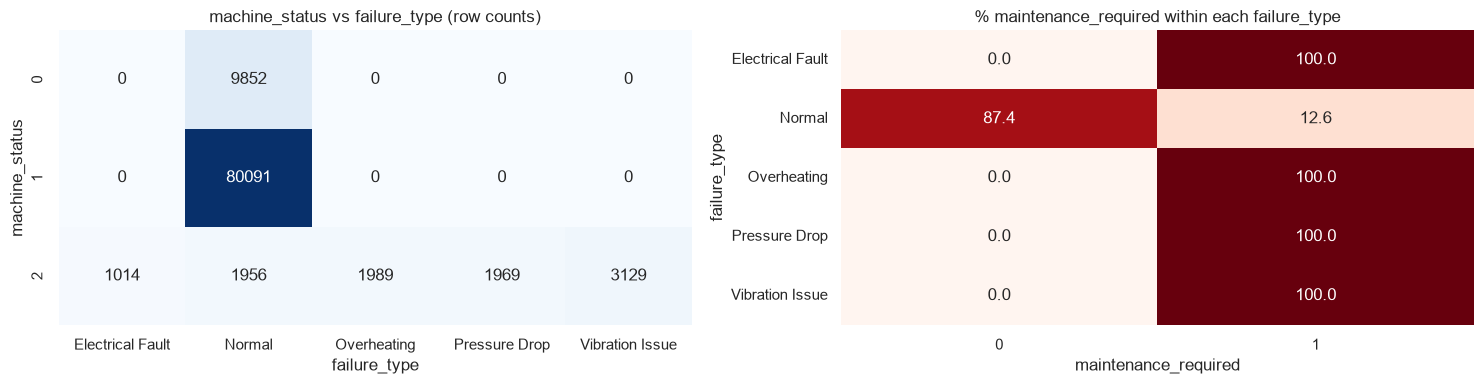

maintenance_required,0,1
machine_status,,
0,89.1,10.9
1,89.3,10.7
2,0.0,100.0


,temperature,vibration_abs,humidity,pressure,energy_consumption
machine_status,,,,,
0,75.13,49.66,54.66,3.01,2.78
1,75.10,50.00,55.03,3.01,2.74
2,74.99,49.92,55.01,2.99,2.74


In [28]:
# 1. downtime_risk vs anomaly_flag
print("Correlation downtime_risk vs anomaly_flag:", round(df["downtime_risk"].corr(df["anomaly_flag"]), 4))
fractional = (df["downtime_risk"] > 0) & (df["downtime_risk"] < 1)
print("Rows where downtime_risk is not exactly 0 or 1:", fractional.sum())

# 2. machine_status vs failure_type, and the maintenance rate in each group
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(pd.crosstab(df["machine_status"], df["failure_type"]),
            annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("machine_status vs failure_type (row counts)")
sns.heatmap(pd.crosstab(df["failure_type"], df[target], normalize="index") * 100,
            annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_title("% maintenance_required within each failure_type")
plt.tight_layout()
plt.show()

display((pd.crosstab(df["machine_status"], df[target], normalize="index") * 100).round(1))

# 3. Are failures visible in the sensors? Compare sensor medians by machine_status
display(df.groupby("machine_status")[sensors].median().round(2))

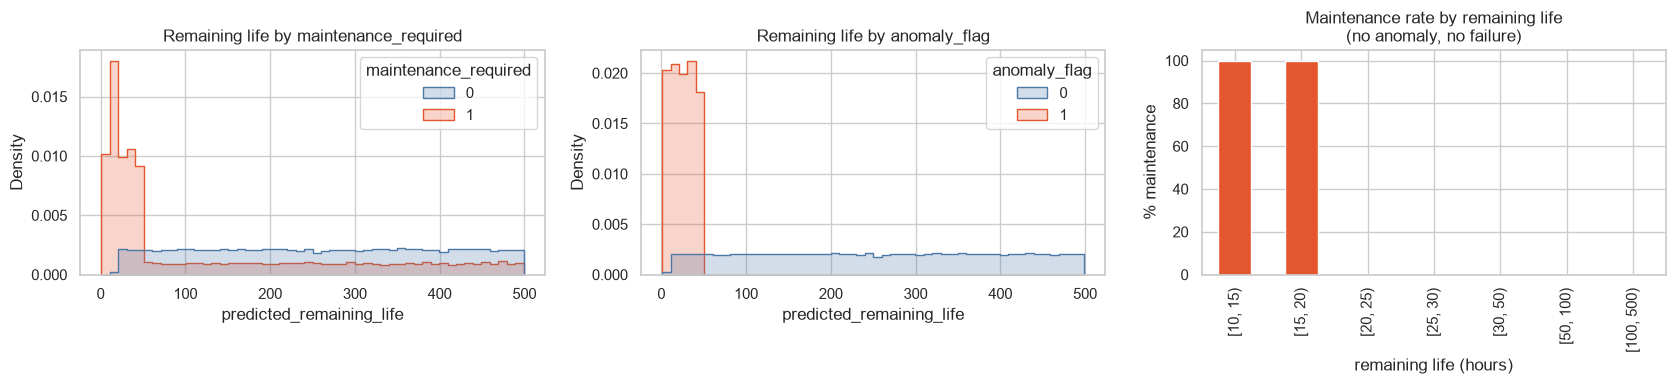

Best cut-off: 20 hours -> accuracy 100.0 %
              min  max   mean
anomaly_flag                 
0              10  499  254.8
1               1   49   25.0


rows  maintenance_rate
anomaly failure low_life                         
False   False   False     80303               0.0
                True       1648               1.0
        True    False      8929               1.0
                True        204               1.0
True    False   False      4861               1.0
                True       3131               1.0
        True    False       575               1.0
                True        349               1.0

Target == (anomaly OR failure OR low life) for 100.0 % of rows
sensor anomaly                   8916
failure only (not an anomaly)    9133
low remaining life only          1648
dtype: int64
sensor anomaly                   45.3
failure only (not an anomaly)    46.4
low remaining life only           8.4
dtype: float64


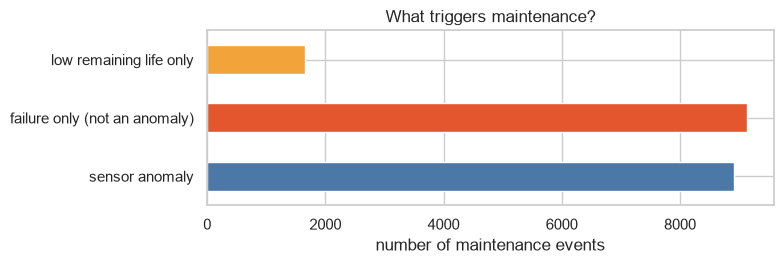

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(data=df, x="predicted_remaining_life", hue=target, palette=["#4C78A8", "#E4572E"],
             bins=50, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Remaining life by maintenance_required")

sns.histplot(data=df, x="predicted_remaining_life", hue="anomaly_flag", palette=["#4C78A8", "#E4572E"],
             bins=50, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Remaining life by anomaly_flag")

# Rows that are neither anomalous nor in failure: where does maintenance switch on?
rest = df[(df["anomaly_flag"] == 0) & (df["machine_status"] != 2)]
life_bins = pd.cut(rest["predicted_remaining_life"], bins=[10, 15, 20, 25, 30, 50, 100, 500], right=False)
(rest.groupby(life_bins, observed=True)[target].mean() * 100).plot(kind="bar", color="#E4572E", ax=axes[2])
axes[2].set(title="Maintenance rate by remaining life\n(no anomaly, no failure)", xlabel="remaining life (hours)", ylabel="% maintenance")
plt.tight_layout()
plt.show()

# Find the best cut-off for remaining life
def accuracy(cutoff):
    return ((rest["predicted_remaining_life"] < cutoff).astype(int) == rest[target]).mean()

cutoff = max(range(5, 40), key=accuracy)
print("Best cut-off:", cutoff, "hours -> accuracy", round(accuracy(cutoff) * 100, 2), "%")
print(df.groupby("anomaly_flag")["predicted_remaining_life"].agg(["min", "max", "mean"]).round(1))

# Break the target down into its three triggers
trigger = pd.DataFrame({
    "anomaly": df["anomaly_flag"] == 1,
    "failure": df["machine_status"] == 2,
    "low_life": df["predicted_remaining_life"] < cutoff,
})
combos = trigger.assign(rows=1, maintenance=df[target]).groupby(["anomaly", "failure", "low_life"]) \
                .agg(rows=("rows", "sum"), maintenance_rate=("maintenance", "mean"))
display(combos)

rule = trigger.any(axis=1).astype(int)
print("Target == (anomaly OR failure OR low life) for", round((rule == df[target]).mean() * 100, 2), "% of rows")

pos = df[target] == 1
share = pd.Series({
    "sensor anomaly": (trigger["anomaly"] & pos).sum(),
    "failure only (not an anomaly)": (~trigger["anomaly"] & trigger["failure"] & pos).sum(),
    "low remaining life only": (~trigger["anomaly"] & ~trigger["failure"] & trigger["low_life"] & pos).sum(),
})
print(share)
print((share / pos.sum() * 100).round(1))
share.plot(kind="barh", color=["#4C78A8", "#E4572E", "#F2A33A"], figsize=(8, 2.8))
plt.xlabel("number of maintenance events")
plt.title("What triggers maintenance?")
plt.tight_layout()
plt.show()

downtime_risk is a near-copy of anomaly_flag (correlation 1.0), so it holds no independent information. failure_type other than Normal occurs only when machine_status is 2 (failure), and in every one of those rows maintenance is required; machine_status = 2 alone also implies maintenance in 100% of rows. These columns describe an event that has already happened, and the sensor medians are the same for idle, running and failing machines, so failures are not visible in the sensors. Among rows with no anomaly and no failure, maintenance is required exactly when predicted_remaining_life is below 20 hours. Overall, maintenance_required equals (anomaly OR failure OR remaining life < 20) for 100% of rows. Only 45.3% of maintenance events are caused by a sensor anomaly; 46.4% come from failures and 8.4% from low remaining life alone, neither of which can be seen in the five sensors. Using downtime_risk, anomaly_flag, machine_status or failure_type as inputs would let a model score almost perfectly without learning anything useful (leakage), so they are excluded. predicted_remaining_life is a legitimate predictor, but because it is itself a prediction from another system, we will report results with and without it.

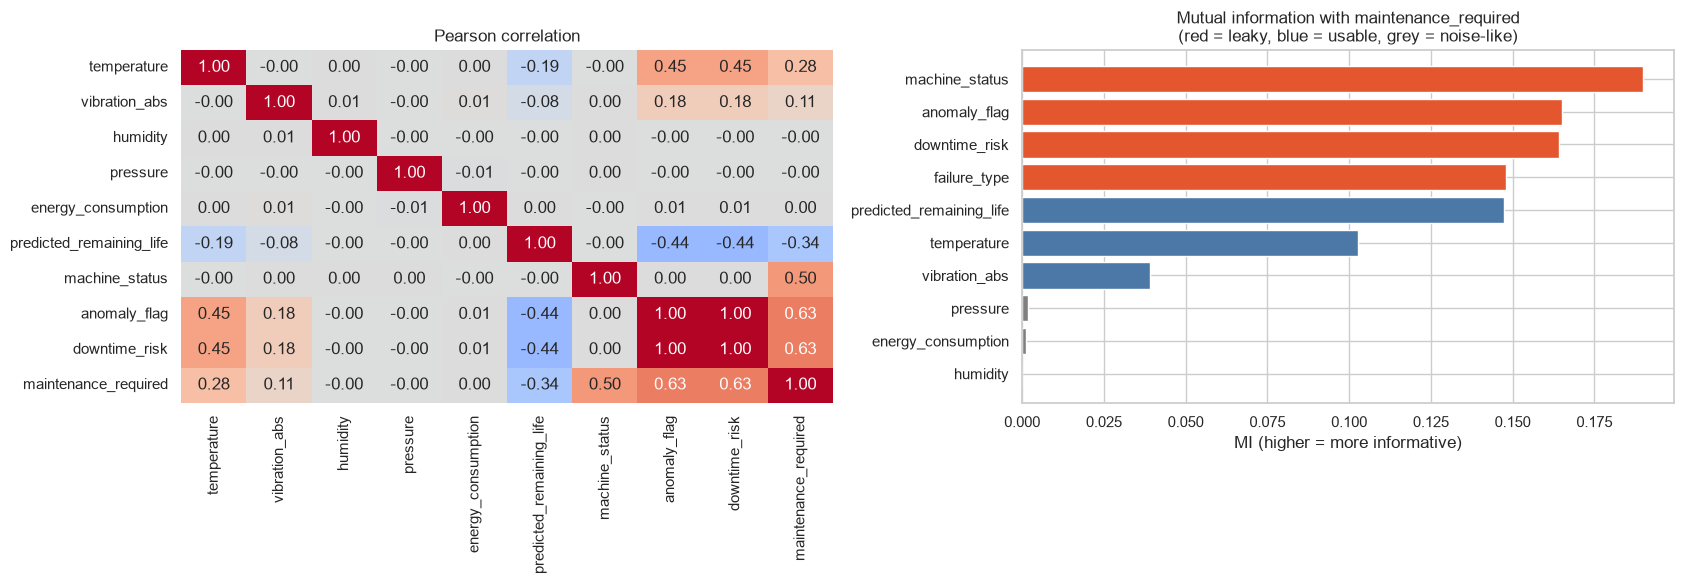

predicted_remaining_life   -0.34
pressure                   -0.00
energy_consumption          0.00
humidity                   -0.00
vibration_abs               0.11
temperature                 0.28
machine_status              0.50
anomaly_flag                0.63
downtime_risk               0.63
maintenance_required        1.00
Name: maintenance_required, dtype: float64
machine_status              0.190
anomaly_flag                0.165
downtime_risk               0.164
failure_type                0.148
predicted_remaining_life    0.147
temperature                 0.103
vibration_abs               0.039
pressure                    0.002
energy_consumption          0.001
humidity                    0.000
dtype: float64


In [30]:
from sklearn.feature_selection import mutual_info_classif

corr_cols = ["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption",
             "predicted_remaining_life", "machine_status", "anomaly_flag", "downtime_risk", target]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Left: Pearson correlation (machine_id is left out because it is a label)
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, cbar=False, ax=axes[0])
axes[0].set_title("Pearson correlation")

# Right: mutual information with the target
X = df[["temperature", "vibration_abs", "humidity", "pressure", "energy_consumption",
        "predicted_remaining_life", "machine_status", "anomaly_flag", "downtime_risk"]].copy()
X["temperature"] = X["temperature"].fillna(X["temperature"].median())   # sklearn cannot take blanks
X["failure_type"] = df["failure_type"].astype("category").cat.codes     # words -> numbers

is_category = [col in ("machine_status", "anomaly_flag", "failure_type") for col in X.columns]
mi = pd.Series(mutual_info_classif(X, df[target], discrete_features=is_category, random_state=SEED),
               index=X.columns).sort_values()

leaky = ["machine_status", "anomaly_flag", "downtime_risk", "failure_type"]
noise = ["humidity", "pressure", "energy_consumption"]
colors = ["#7F7F7F" if c in noise else "#E4572E" if c in leaky else "#4C78A8" for c in mi.index]

axes[1].barh(mi.index, mi.values, color=colors)
axes[1].set(title="Mutual information with maintenance_required\n(red = leaky, blue = usable, grey = noise-like)",
            xlabel="MI (higher = more informative)")
plt.tight_layout()
plt.show()

print(df[corr_cols].corr()[target].round(2).sort_values())
print(mi.round(3).sort_values(ascending=False))

The five sensors are uncorrelated with each other (all |r| ≤ 0.01), so there is no multicollinearity to handle. The columns most related to the target are the derived ones (machine_status, anomaly_flag, downtime_risk, failure_type), consistent with the leakage found in Step E, and predicted_remaining_life (r = -0.34: less life left means more maintenance). Among the raw sensors, temperature (MI ≈ 0.10) and vibration size (MI ≈ 0.04) carry real information through their thresholds, while humidity, pressure and energy consumption have MI ≈ 0 and correlation 0.00, so they behave like noise. Temperature's linear correlation (0.28) understates its effect because the relationship is a sharp step at 90 °C, which is why we also use mutual information and tree-based models.

# Summary of Key Findings

## What we found

| # | Finding | Evidence | What we do about it |
|---|---------|----------|---------------------|
| 1 | The data is complete apart from one column | 100,000 rows, 13 columns, one reading per minute (1 Jan to 11 Mar 2025), 50 machines, 0 duplicate rows | No rows need removing |
| 2 | `temperature` is 14% missing, and the gaps are random | Missing rate is about 14% in every group, chi-square p-values 0.31 to 0.90; mean and median fills have the same error | Fill with the **median** plus a `temp_missing` marker (median taken from training data only) |
| 3 | 6.7% of `vibration` readings are negative, which is impossible | They are about 6.7% in every status, failure type and maintenance group (p > 0.5), and the negative-to-positive ratio is about 0.07 at every vibration level | Random sign errors, so use `vibration_abs`; no rows deleted |
| 4 | Sensors have different shapes | Temperature and `vibration_abs` are bell-shaped; humidity, pressure and energy are flat across their ranges | Humidity, pressure and energy behave like noise (see 9) |
| 5 | The target is imbalanced | 19.7% need maintenance (about 4 : 1); always predicting "no" is 80.3% accurate | Use recall, precision, F1 and PR-AUC, not accuracy; stratified split |
| 6 | Machine and time carry no signal | Maintenance rate by machine p = 0.238, by hour p = 0.35, flat by day | Do not use `machine_id` or time as predictors |
| 7 | Sensors only help through extreme readings | Temperature (effect size 0.34) and vibration (0.12) differ by target, but once anomalous rows are removed all effect sizes fall below 0.01 | Expect limited power from sensors alone |
| 8 | `anomaly_flag` is a simple rule | Flagged when temperature is above 90 °C or vibration size is above 80 mm/s; only 5 of 86,000 rows disagree, all exactly on a threshold | Engineer threshold flags; do not use `anomaly_flag` as an input |
| 9 | Some derived columns give away the answer (leakage) | `downtime_risk` is a copy of `anomaly_flag` (r = 1.0); `machine_status` = 2 and every fault type always mean maintenance | Exclude `downtime_risk`, `anomaly_flag`, `machine_status` and `failure_type` |
| 10 | The target follows a hidden rule | Maintenance = anomaly OR failure OR remaining life below 20 hours, true for 100% of rows | `predicted_remaining_life` is a legitimate predictor; report results with and without it |
| 11 | Sensors have a built-in ceiling | Of all maintenance events, 45.3% are sensor anomalies, 46.4% are failures not visible in the sensors, 8.4% are low remaining life only; 922 anomalies (10.3%) are hidden by missing temperature | A sensor-only model can detect at most about 45% of events; state this honestly |
| 12 | The sensors are independent of each other | All sensor-to-sensor correlations are 0.00 to 0.01; humidity, pressure and energy have mutual information near 0 | No multicollinearity to fix; those three are candidates for removal |

## Engineered features and why

| Feature | How it is built | Why |
|---------|-----------------|-----|
| `vibration_abs` | absolute value of `vibration` | Removes random sign errors and keeps all rows; the anomaly flag also uses vibration size |
| `temp_missing` | 1 if temperature was missing, else 0 | Tells a model when the temperature was filled in rather than measured |
| `temp_over_90` | 1 if temperature is above 90 °C | Makes the 90 °C anomaly threshold explicit for models that cannot learn thresholds easily |
| `vib_abs_over_80` | 1 if `vibration_abs` is above 80 | Makes the 80 mm/s threshold explicit |